In [2]:
from preprocessing import save_tiff, load_tiff, normalize_image, parse_path
from skimage import io
from segmentation import otsu_thresholding
from plotting import plot_segmentation_results

In [3]:
path = "C:/Fortescue_apps/Code/FZ_Code/test_images/TLD_Fresh_LFP_11.tif"
detector, state, chemistry, image_ID = parse_path(path)
print(f"Detector: {detector}, State: {state}, Chemistry: {chemistry}, Image ID: {image_ID}")

Detector: TLD, State: Fresh, Chemistry: LFP, Image ID: 11


In [4]:
import numpy as np
loaded_image = load_tiff(path)
print(f"Shape: {loaded_image.shape}, Data Type: {loaded_image.dtype}")

loaded_image = loaded_image.astype(np.float32) # Convert to float32 for normalization
low, high = loaded_image.min(), loaded_image.max()
print(f"Min: {low}, Max: {high}")

Shape: (1010, 1536), Data Type: uint16
Min: 0.0, Max: 65535.0


In [9]:
normalised_image = normalize_image(loaded_image)
normalised_image_1 = normalize_image(loaded_image, (1, 99))

mask, threshold = otsu_thresholding(normalised_image)
mask_1, threshold_1 = otsu_thresholding(normalised_image_1)
mask_2, threshold_2 = otsu_thresholding(loaded_image)

#save_tiff(normalised_image, "C:/Fortescue_apps/Code/FZ_Code/test_images/TLD_Fresh_LFP_11_normalised.tif")


Image shape: (1010, 1536), Image dtype: float32
Image shape: (1010, 1536), Image dtype: float32


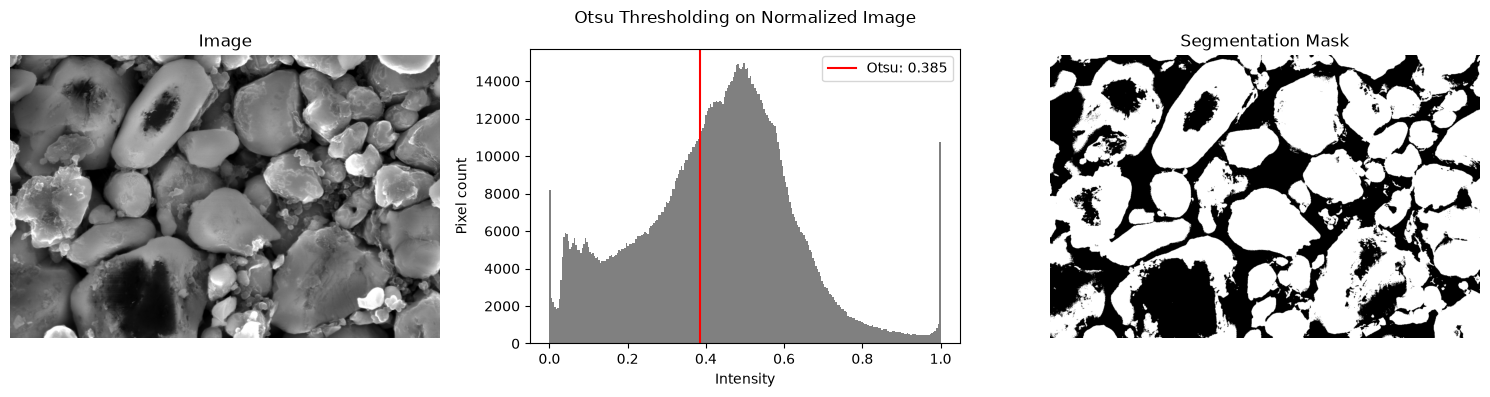

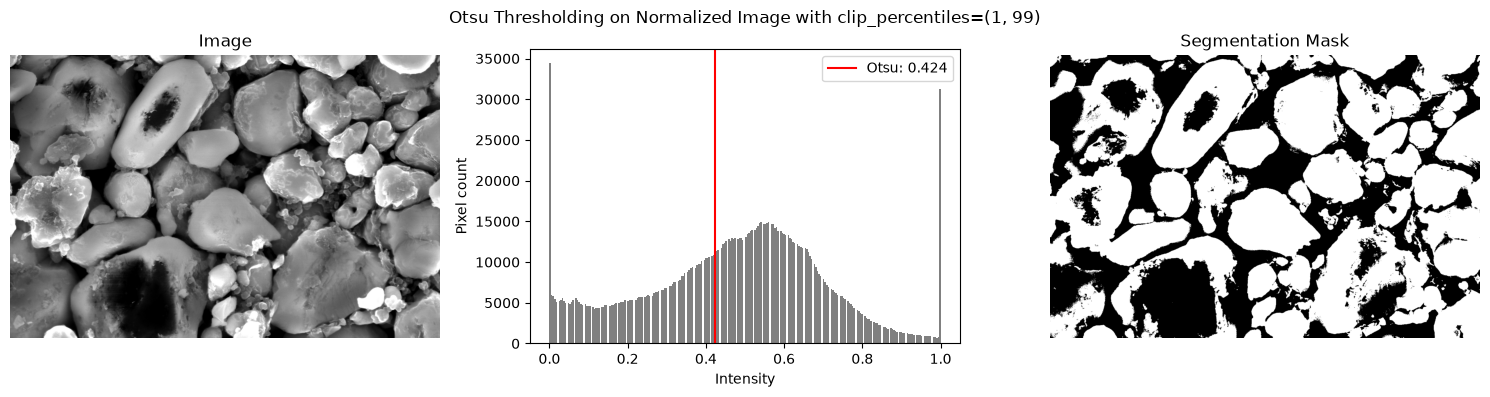

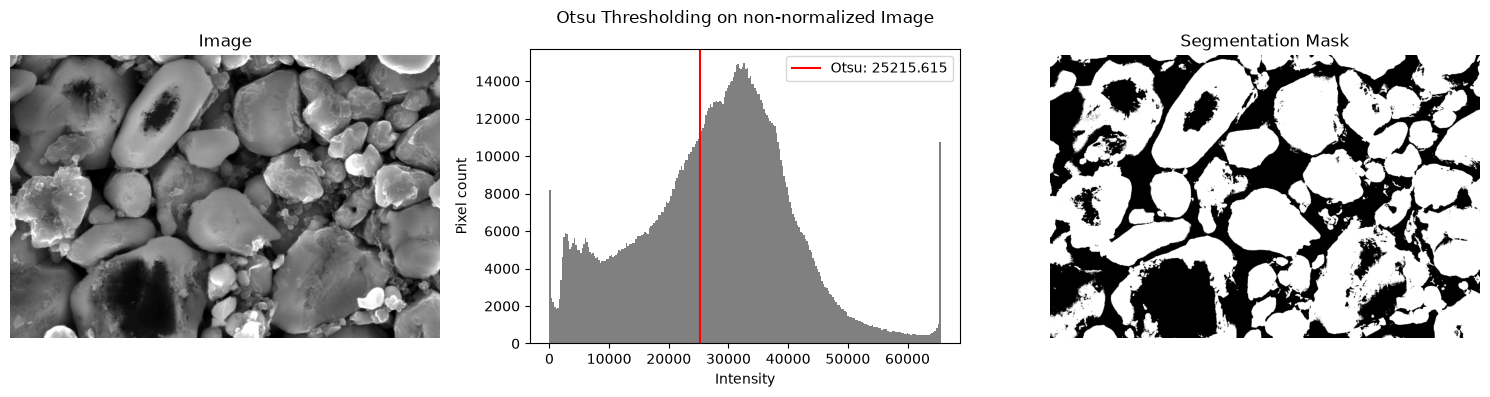

(<Figure size 1500x400 with 3 Axes>,
 array([<Axes: title={'center': 'Image'}>,
        <Axes: xlabel='Intensity', ylabel='Pixel count'>,
        <Axes: title={'center': 'Segmentation Mask'}>], dtype=object))

In [8]:
plot_segmentation_results(normalised_image, mask, threshold, title="Otsu Thresholding on Normalized Image")
plot_segmentation_results(normalised_image_1, mask_1, threshold_1, title="Otsu Thresholding on Normalized Image with clip_percentiles=(1, 99)")
plot_segmentation_results(loaded_image, mask_2, threshold_2, title="Otsu Thresholding on non-normalized Image")

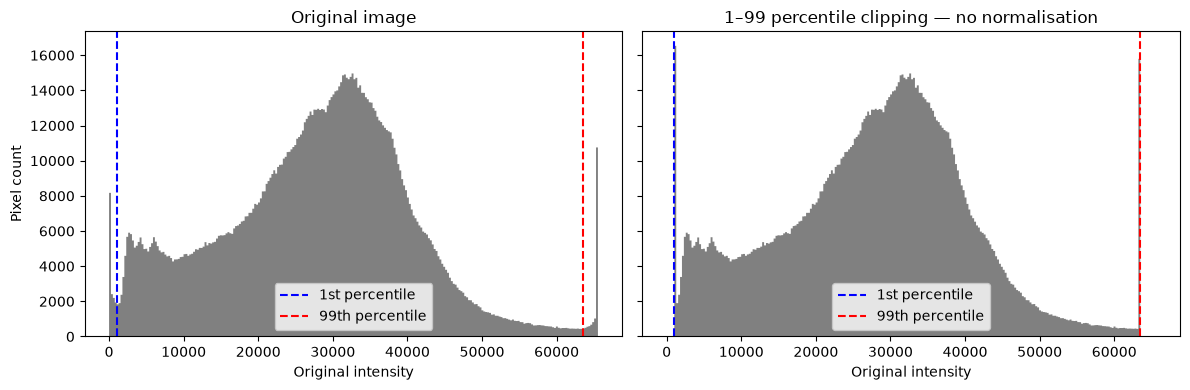

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Clip at the 1st and 99th percentiles — no normalisation
low, high = np.percentile(loaded_image, [1, 99])
clipped_image = np.clip(loaded_image, low, high)

# Same bins and axes for comparison
bins = np.histogram_bin_edges(loaded_image, bins=256)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4), sharex=True, sharey=True
)

for ax, image, title in zip(
    axes,
    [loaded_image, clipped_image],
    ["Original image", "1–99 percentile clipping — no normalisation"]
):
    ax.hist(
        image.ravel(), bins=bins,
        histtype="stepfilled", color="gray", edgecolor="none"
    )
    ax.axvline(low, color="blue", linestyle="--", label="1st percentile")
    ax.axvline(high, color="red", linestyle="--", label="99th percentile")
    ax.set_title(title)
    ax.set_xlabel("Original intensity")
    ax.legend()

axes[0].set_ylabel("Pixel count")
fig.tight_layout()
plt.show()

Image shape: (1010, 1536), Image dtype: float32
Image shape: (1010, 1536), Image dtype: float32


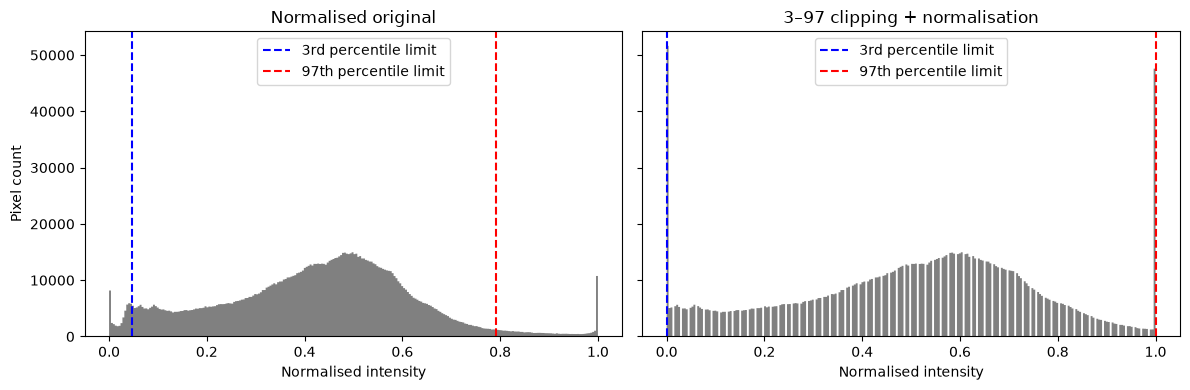

In [12]:
import numpy as np
import matplotlib.pyplot as plt

normalised_image = normalize_image(loaded_image)
normalised_clipped_image = normalize_image(loaded_image, (3, 97))

# Percentile positions on the normalised original
low, high = np.percentile(normalised_image, [3, 97])

# Identical bins across 0–1
bins = np.linspace(0, 1, 257)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4), sharex=True, sharey=True
)

for ax, image, title, limits in zip(
    axes,
    [normalised_image, normalised_clipped_image],
    ["Normalised original", "3–97 clipping + normalisation"],
    [(low, high), (0, 1)]
):
    ax.hist(
        image.ravel(), bins=bins,
        histtype="stepfilled", color="gray", edgecolor="none"
    )
    ax.axvline(
        limits[0], color="blue", linestyle="--",
        label="3rd percentile limit"
    )
    ax.axvline(
        limits[1], color="red", linestyle="--",
        label="97th percentile limit"
    )
    ax.set_title(title)
    ax.set_xlabel("Normalised intensity")
    ax.legend()

axes[0].set_ylabel("Pixel count")
fig.tight_layout()
plt.show()